# TRUSTSR Lab 03.02 — Failure Recording and Recovery

**Project:** TRUSTSR — Trust-Aware Causal Semantic Recovery for Long-Horizon Agentic Systems  
**Phase:** Lab 03 — Reliability and evidence integrity  
**Status:** Synthetic local prototype | Version 0.1.0

## Motivation
Lab 03.01 wrote checkpoint state and successful/rejected decision records in one SQLite transaction. When an injected exception occurred before commit, the transaction correctly rolled back—but the failed attempt also left no audit record.

This lab tests a two-stage design:
1. Attempt the checkpoint change and its decision event in one SQLite transaction.
2. If that transaction rolls back, record a separate `operational_failure` event in a new transaction.

The second event is not atomic with the failed transaction; it is a best-effort post-rollback record. If the process dies before this second transaction, the failure event can still be absent. We will make that limitation explicit.

## Tests
- Accepted, stale/replayed, and injected pre-commit failure.
- Checkpoint state remains unchanged after the injected failure.
- A separate failure event records the failure and unchanged state.
- Reopen database and verify state, rows, and hash chain.
- Simulate failure of the post-rollback logger and document the resulting evidence gap.
- Assertions, plot, and CSV exports.

**Evidence boundary:** Synthetic local SQLite simulation only. No production reliability or universal audit completeness claim.

> **Revision note (v0.1.1 package review).** The expected audit-row delta for an injected pre-commit failure was 2 but the design (rollback, then one separate failure record) yields 1. Corrected the expectation.

## 1. Imports and database setup

In [1]:
import os, json, sqlite3, tempfile, hashlib, uuid, sys, platform
from datetime import datetime, timezone
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("SQLite:", sqlite3.sqlite_version)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence classification: synthetic local simulation")

fd, DB_PATH = tempfile.mkstemp(prefix="trustsr_lab03_02_", suffix=".sqlite")
os.close(fd)

def open_db():
    c = sqlite3.connect(DB_PATH, timeout=10, isolation_level=None)
    c.execute("PRAGMA journal_mode=WAL")
    c.execute("PRAGMA synchronous=FULL")
    c.execute("CREATE TABLE IF NOT EXISTS checkpoint_state (singleton_id INTEGER PRIMARY KEY CHECK(singleton_id=1), high_water_mark INTEGER NOT NULL CHECK(high_water_mark>=0))")
    c.execute("INSERT OR IGNORE INTO checkpoint_state VALUES (1, 0)")
    c.execute("CREATE TABLE IF NOT EXISTS audit_events (sequence INTEGER PRIMARY KEY AUTOINCREMENT, transaction_id TEXT NOT NULL, timestamp_utc TEXT NOT NULL, checkpoint_version INTEGER, outcome TEXT NOT NULL, reason TEXT NOT NULL, mark_before INTEGER NOT NULL, mark_after INTEGER NOT NULL, previous_hash TEXT NOT NULL, event_hash TEXT NOT NULL)")
    return c

conn = open_db()
print("Database initialized; mark =", conn.execute("SELECT high_water_mark FROM checkpoint_state").fetchone()[0])

Python: 3.12.3
SQLite: 3.45.1
Execution UTC: 2026-10-11T10:26:34.378162+00:00
Evidence classification: synthetic local simulation
Database initialized; mark = 0


## 2. Hash-chain utilities

In [2]:
GENESIS_HASH = "0" * 64
FIELDS = ["sequence","transaction_id","timestamp_utc","checkpoint_version","outcome","reason","mark_before","mark_after","previous_hash"]

def canonical_bytes(value):
    return json.dumps(value, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode("utf-8")

def hash_event(event):
    return hashlib.sha256(canonical_bytes(event)).hexdigest()

def fetch_events():
    rows = conn.execute("SELECT sequence, transaction_id, timestamp_utc, checkpoint_version, outcome, reason, mark_before, mark_after, previous_hash, event_hash FROM audit_events ORDER BY sequence").fetchall()
    return [dict(zip(FIELDS + ["event_hash"], row)) for row in rows]

def verify_chain(log):
    issues, prev = [], GENESIS_HASH
    for seq, stored in enumerate(log, start=1):
        event = {key: stored[key] for key in FIELDS}
        if event["sequence"] != seq:
            issues.append("sequence_gap_or_reordering")
        if event["previous_hash"] != prev:
            issues.append("previous_hash_mismatch")
        if stored["event_hash"] != hash_event(event):
            issues.append("event_hash_mismatch")
        prev = stored["event_hash"]
    return {"valid": not issues, "issues": issues, "events_checked": len(log)}

def insert_event_in_open_transaction(txid, version, outcome, reason, before, after):
    last = conn.execute("SELECT event_hash FROM audit_events ORDER BY sequence DESC LIMIT 1").fetchone()
    prev = last[0] if last else GENESIS_HASH
    seq = int(conn.execute("SELECT COALESCE(MAX(sequence),0)+1 FROM audit_events").fetchone()[0])
    event = {"sequence":seq,"transaction_id":txid,"timestamp_utc":datetime.now(timezone.utc).isoformat(),
             "checkpoint_version":version,"outcome":outcome,"reason":reason,
             "mark_before":before,"mark_after":after,"previous_hash":prev}
    conn.execute("INSERT INTO audit_events (sequence,transaction_id,timestamp_utc,checkpoint_version,outcome,reason,mark_before,mark_after,previous_hash,event_hash) VALUES (?,?,?,?,?,?,?,?,?,?)",
                 (seq,txid,event["timestamp_utc"],version,outcome,reason,before,after,prev,hash_event(event)))

print("Hash-chain utilities ready.")

Hash-chain utilities ready.


## 3. Checkpoint operation and separate failure recorder

In [3]:
def record_operational_failure(version, before, reason, *, simulate_logger_failure=False):
    # Separate transaction after the checkpoint transaction has rolled back.
    if simulate_logger_failure:
        return {"recorded": False, "reason": "simulated_failure_recorder_unavailable"}
    txid = "failure-" + str(uuid.uuid4())
    conn.execute("BEGIN IMMEDIATE")
    try:
        insert_event_in_open_transaction(txid, version, "operational_failure", reason, before, before)
        conn.execute("COMMIT")
        return {"recorded": True, "transaction_id": txid, "reason": reason}
    except Exception:
        conn.execute("ROLLBACK")
        raise

def submit_version(version, *, inject_precommit_failure=False, simulate_logger_failure=False):
    txid = str(uuid.uuid4())
    conn.execute("BEGIN IMMEDIATE")
    before = int(conn.execute("SELECT high_water_mark FROM checkpoint_state WHERE singleton_id=1").fetchone()[0])
    valid = isinstance(version, int) and not isinstance(version, bool) and version >= 1
    accepted = valid and version > before
    if not valid:
        outcome, reason, after = "rejected", "invalid_version", before
    elif accepted:
        outcome, reason, after = "accepted", "committed", version
        conn.execute("UPDATE checkpoint_state SET high_water_mark=? WHERE singleton_id=1", (version,))
    else:
        outcome, reason, after = "rejected", "stale_or_replay", before

    try:
        if inject_precommit_failure:
            raise RuntimeError("injected_precommit_failure")
        insert_event_in_open_transaction(txid, version if valid else None, outcome, reason, before, after)
        conn.execute("COMMIT")
        return {"accepted": bool(accepted), "reason": reason, "mark_before": before, "mark_after": after, "failure_recorded": None}
    except Exception as exc:
        conn.execute("ROLLBACK")
        unchanged = int(conn.execute("SELECT high_water_mark FROM checkpoint_state WHERE singleton_id=1").fetchone()[0])
        failure_result = record_operational_failure(version if valid else None, unchanged, str(exc), simulate_logger_failure=simulate_logger_failure)
        return {"accepted": False, "reason": str(exc), "mark_before": before, "mark_after": unchanged, "failure_recorded": failure_result["recorded"], "failure_record_reason": failure_result["reason"]}

print("Submit and post-rollback failure recorder defined.")

Submit and post-rollback failure recorder defined.


## 4. Run synthetic scenarios

In [4]:
rows = []

def case(name, version, expected_accept, expected_mark, inject=False, logger_failure=False, expected_failure_record=None):
    before_events = int(conn.execute("SELECT COUNT(*) FROM audit_events").fetchone()[0])
    result = submit_version(version, inject_precommit_failure=inject, simulate_logger_failure=logger_failure)
    after_events = int(conn.execute("SELECT COUNT(*) FROM audit_events").fetchone()[0])
    # A rolled-back attempt leaves only the separate operational_failure row (1) when the recorder works, none (0) if it also fails.
    expected_rows = 0 if (inject and logger_failure) else 1
    checks = {
        "acceptance": result["accepted"] == expected_accept,
        "mark": result["mark_after"] == expected_mark,
        "event_delta": after_events - before_events == expected_rows
    }
    if expected_failure_record is not None:
        checks["failure_record"] = result["failure_recorded"] == expected_failure_record
    row = {"scenario":name,"version":version,"accepted":result["accepted"],"reason":result["reason"],
           "mark_before":result["mark_before"],"mark_after":result["mark_after"],
           "audit_rows_before":before_events,"audit_rows_after":after_events,"audit_row_delta":after_events-before_events,
           "failure_recorded":result.get("failure_recorded"),"checks_passed":all(checks.values())}
    rows.append(row)
    assert row["checks_passed"], row
    return result

case("accept_v2", 2, True, 2)
case("reject_stale_v1", 1, False, 2)
case("precommit_failure_with_failure_record", 4, False, 2, inject=True, expected_failure_record=True)
case("accept_v3", 3, True, 3)
case("precommit_failure_logger_also_fails", 5, False, 3, inject=True, logger_failure=True, expected_failure_record=False)

scenario_df = pd.DataFrame(rows)
display(scenario_df)
print("Final high-water mark:", conn.execute("SELECT high_water_mark FROM checkpoint_state").fetchone()[0])
display(pd.DataFrame(fetch_events()))

                                scenario  version  accepted                      reason  mark_before  mark_after  audit_rows_before  audit_rows_after  audit_row_delta failure_recorded  checks_passed
0                              accept_v2        2      True                   committed            0           2                  0                 1                1             None           True
1                        reject_stale_v1        1     False             stale_or_replay            2           2                  1                 2                1             None           True
2  precommit_failure_with_failure_record        4     False  injected_precommit_failure            2           2                  2                 3                1             True           True
3                              accept_v3        3      True                   committed            2           3                  3                 4                1             None           True
4    

Final high-water mark: 3


   sequence                                transaction_id                     timestamp_utc  checkpoint_version              outcome                      reason  mark_before  mark_after  \
0         1          902cca00-8158-4f29-b890-5580f12df89d  2026-10-11T10:26:34.386052+00:00                   2             accepted                   committed            0           2   
1         2          59e2dffe-dd31-416f-9ba5-d3ee947f5184  2026-10-11T10:26:34.386876+00:00                   1             rejected             stale_or_replay            2           2   
2         3  failure-941dccf0-df82-4233-b943-b91bb4c1abdf  2026-10-11T10:26:34.387458+00:00                   4  operational_failure  injected_precommit_failure            2           2   
3         4          87ea15cc-7a3d-49b2-9ae8-a7562b9a6309  2026-10-11T10:26:34.387915+00:00                   3             accepted                   committed            2           3   

                                                      

## 5. Verify audit chain and restart persistence

In [5]:
events = fetch_events()
chain_result = verify_chain(events)
print("Chain verification:", chain_result)
assert chain_result["valid"]

mark_before = int(conn.execute("SELECT high_water_mark FROM checkpoint_state").fetchone()[0])
count_before = len(events)
conn.close()
conn = open_db()
mark_after = int(conn.execute("SELECT high_water_mark FROM checkpoint_state").fetchone()[0])
events_after = fetch_events()
restart_result = {"mark_before_restart":mark_before,"mark_after_restart":mark_after,
                  "events_before_restart":count_before,"events_after_restart":len(events_after),
                  "state_persisted":mark_before==mark_after,"events_persisted":count_before==len(events_after),
                  "chain_valid_after_restart":verify_chain(events_after)["valid"]}
display(pd.DataFrame([restart_result]))
assert restart_result["state_persisted"] and restart_result["events_persisted"] and restart_result["chain_valid_after_restart"]

Chain verification: {'valid': True, 'issues': [], 'events_checked': 4}


   mark_before_restart  mark_after_restart  events_before_restart  events_after_restart  state_persisted  events_persisted  chain_valid_after_restart
0                    3                   3                      4                     4             True              True                       True

## 6. Tampering check

In [6]:
tampered = [dict(e) for e in events_after]
tampered[0]["reason"] = "modified_event"
tamper_result = verify_chain(tampered)
print("Tamper detection:", tamper_result)
assert not tamper_result["valid"]

validation_df = pd.DataFrame([
    {"test":"intact_chain","passed":verify_chain(events_after)["valid"]},
    {"test":"modified_payload_detected","passed":not tamper_result["valid"]},
    {"test":"restart_state_persisted","passed":restart_result["state_persisted"]},
    {"test":"restart_events_persisted","passed":restart_result["events_persisted"]},
    {"test":"logger_failure_gap_is_visible","passed":any(r["scenario"]=="precommit_failure_logger_also_fails" and r["failure_recorded"] is False for r in rows)}
])
display(validation_df)

Tamper detection: {'valid': False, 'issues': ['event_hash_mismatch'], 'events_checked': 4}


                            test  passed
0                   intact_chain    True
1      modified_payload_detected    True
2        restart_state_persisted    True
3       restart_events_persisted    True
4  logger_failure_gap_is_visible    True

## 7. Plot and export CSVs

CSV exports created: trustsr_lab03_02_failure_scenarios.csv, trustsr_lab03_02_audit_events.csv, trustsr_lab03_02_validation.csv, trustsr_lab03_02_restart_results.csv


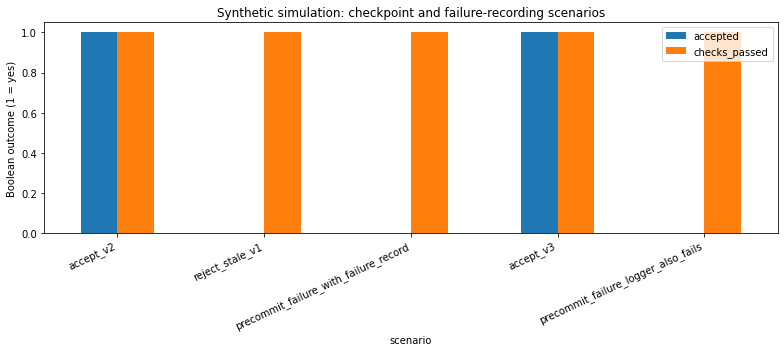

In [7]:
ax = scenario_df.set_index("scenario")[["accepted","checks_passed"]].astype(int).plot(kind="bar", figsize=(11,5))
ax.set_title("Synthetic simulation: checkpoint and failure-recording scenarios")
ax.set_ylabel("Boolean outcome (1 = yes)")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

scenario_df.to_csv("trustsr_lab03_02_failure_scenarios.csv", index=False)
pd.DataFrame(events_after).to_csv("trustsr_lab03_02_audit_events.csv", index=False)
validation_df.to_csv("trustsr_lab03_02_validation.csv", index=False)
pd.DataFrame([restart_result]).to_csv("trustsr_lab03_02_restart_results.csv", index=False)
print("CSV exports created: trustsr_lab03_02_failure_scenarios.csv, trustsr_lab03_02_audit_events.csv, trustsr_lab03_02_validation.csv, trustsr_lab03_02_restart_results.csv")

## 8. Final assertions

In [8]:
assert scenario_df["checks_passed"].all()
assert conn.execute("SELECT high_water_mark FROM checkpoint_state WHERE singleton_id=1").fetchone()[0] == 3
assert verify_chain(fetch_events())["valid"]
assert restart_result["state_persisted"] and restart_result["events_persisted"]
assert validation_df["passed"].all()
assert sum(e["outcome"] == "operational_failure" for e in fetch_events()) == 1
print("PASS: successful/rejected decisions are transactionally audited.")
print("PASS: injected pre-commit failure is recorded in a separate post-rollback transaction.")
print("PASS: failure-recorder failure is explicitly exposed as an evidence gap.")
print("PASS: persisted audit chain validates after restart; payload tampering is detected.")
print("All TRUSTSR Lab 03.02 assertions passed.")

PASS: successful/rejected decisions are transactionally audited.
PASS: injected pre-commit failure is recorded in a separate post-rollback transaction.
PASS: failure-recorder failure is explicitly exposed as an evidence gap.
PASS: persisted audit chain validates after restart; payload tampering is detected.
All TRUSTSR Lab 03.02 assertions passed.


## 9. Interpretation and limitations

### What this synthetic test demonstrates
When the checkpoint transaction fails before commit, state changes roll back. A second transaction can then record an `operational_failure` event. The scenario that also disables this recorder shows that the second-stage log is best-effort and can be missing.

### Remaining design choices
- For stronger guarantees, consider a durable external logging channel or watchdog/supervisor that records process failures independently.
- A failure record written after rollback cannot be atomic with the transaction that failed.
- If the process terminates abruptly before the recorder executes, the failure event may not exist.
- A privileged attacker who can rewrite the database may alter events and hashes; independent trusted-head anchoring remains out of scope.

### Defensible research wording
“In the tested synthetic local scenarios, post-rollback failure recording captured an injected pre-commit failure when the recorder was available. A separately simulated recorder failure left the failure event absent, exposing the design's remaining observability gap.”
This is not a production guarantee or a real crash test.